# QueueWise — Smart Queue Monitoring & Waiting Time Estimation (versi sederhana)
**Mata kuliah:** Computer Vision · **Tugas:** Week 8 — Progress Submission
**Kelompok:** _isi_ · **Anggota:** _Nama – NIM_

Alur sistem (satu loket, FIFO):

```
Video -> YOLO11n (deteksi orang) -> ByteTrack (ID per orang) -> titik kaki
      -> lewat ENTRY LINE  = masuk antrean (+1)
      -> lewat EXIT LINE   = selesai dilayani (-1), waktu tunggu dicatat
      -> antrean = masuk - keluar - hilang ; estimasi tunggu = antrean x selang rata-rata antar-keluar
      -> overlay dashboard + video output + log CSV
```

Notebook ini **berdiri sendiri**: tidak butuh file `configs/*.json` atau `tests/*.py`. Semua parameter ada di cell **KONFIGURASI**.
Jalankan dengan **Kernel → Restart & Run All**.

> Catatan data: video default `vtest.avi` (contoh resmi OpenCV) berisi pejalan kaki, **bukan antrean sungguhan**.
> Video ini dipakai untuk membuktikan deteksi, tracking, dan penghitungan garis bekerja. Untuk Week 9 ganti dengan video antrean milik kelompok.

## 1. Setup & import

In [94]:
# (pip install dilewati saat tes)

In [95]:
# Jalankan sekali bila library belum terpasang:
# !pip install ultralytics lap opencv-python pandas matplotlib

import time, urllib.request
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

OUT = Path("outputs"); (OUT / "screenshots").mkdir(parents=True, exist_ok=True)

def show(img, title=""):
    plt.figure(figsize=(9, 6)); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.title(title); plt.axis("off"); plt.show()

print("OpenCV", cv2.__version__)

OpenCV 4.14.0


## 2. Konfigurasi
Semua yang perlu diubah untuk video lain ada di sini. Setiap garis didefinisikan dengan dua titik (`p1`, `p2`)
dan satu **`after`**: titik contoh di sisi yang dicapai orang **setelah** melewati garis dengan arah yang benar.
Dengan cara ini arah valid tidak perlu ditebak dengan tanda `+1/-1`.

In [96]:
VIDEO_PATH = Path("vtest.avi")      # ganti ke video antrean kelompok, atau 0 untuk webcam
VIDEO_URL  = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/vtest.avi"

MODEL_NAME = "yolo11n.pt"           # diunduh otomatis oleh Ultralytics
CONF       = 0.30                   # ambang confidence deteksi
TRACKER    = "bytetrack.yaml"

# Untuk vtest.avi: orang berjalan dari kanan ke kiri dianggap "mengantre".
ENTRY_LINE = {"p1": (600, 140), "p2": (600, 480), "after": (500, 300)}   # garis merah 1 (masuk)
EXIT_LINE  = {"p1": (300, 170), "p2": (300, 430), "after": (200, 300)}   # garis merah 2 (selesai)

DEADBAND_PX    = 6     # pita mati di sekitar garis -> getaran bbox tidak memicu crossing
LOST_TIMEOUT_S = 5.0   # orang di antrean yang hilang dari kamera > 5 s dikeluarkan (status LOST)
MAX_FRAMES     = None  # None = seluruh video; isi angka (mis. 300) untuk uji cepat / webcam

## 3. Load video & metadata (preprocessing)

768x576 | 10.0 FPS | 795 frame | 79.5 detik


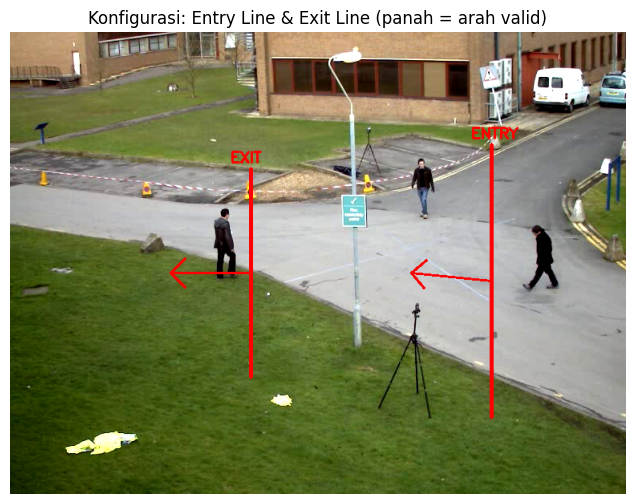

In [97]:
if isinstance(VIDEO_PATH, Path) and not VIDEO_PATH.exists():
    print("Mengunduh video contoh OpenCV ...")
    urllib.request.urlretrieve(VIDEO_URL, VIDEO_PATH)

SRC = str(VIDEO_PATH) if isinstance(VIDEO_PATH, Path) else VIDEO_PATH
cap = cv2.VideoCapture(SRC)
assert cap.isOpened(), f"Video tidak bisa dibuka: {SRC}"
FPS = cap.get(cv2.CAP_PROP_FPS) or 30.0          # webcam kadang mengembalikan 0
N_FRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
ok, FIRST = cap.read(); cap.release()
assert ok, "Frame pertama tidak terbaca"
print(f"{W}x{H} | {FPS:.1f} FPS | {N_FRAMES} frame | {N_FRAMES / FPS:.1f} detik")

def draw_lines(img):
    for line, name in ((ENTRY_LINE, "ENTRY"), (EXIT_LINE, "EXIT")):
        cv2.line(img, line["p1"], line["p2"], (0, 0, 255), 3)
        mx, my = (line["p1"][0] + line["p2"][0]) // 2, (line["p1"][1] + line["p2"][1]) // 2
        cv2.arrowedLine(img, (mx, my), line["after"], (0, 0, 255), 2, tipLength=0.25)   # arah valid
        cv2.putText(img, name, (line["p1"][0] - 25, line["p1"][1] - 8), 0, 0.6, (0, 0, 255), 2)
    return img

geo = draw_lines(FIRST.copy())
cv2.imwrite(str(OUT / "screenshots/01_konfigurasi_garis.jpg"), geo)
show(geo, "Konfigurasi: Entry Line & Exit Line (panah = arah valid)")

## 4. Model YOLO & uji deteksi satu frame
Model pretrained COCO, hanya kelas `0 = person`. Tidak ada training ulang. Resize ke 640 dilakukan internal oleh YOLO
(letterbox), jadi koordinat garis tetap memakai resolusi asli video.

Orang terdeteksi di frame 0: 3


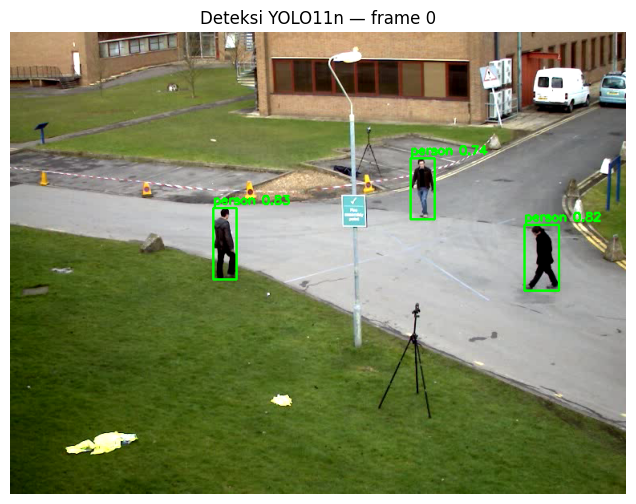

In [98]:
model = YOLO(MODEL_NAME)
det = model.predict(FIRST, classes=[0], conf=CONF, verbose=False)[0]
img = FIRST.copy()
for (x1, y1, x2, y2), c in zip(det.boxes.xyxy.int().tolist(), det.boxes.conf.tolist()):
    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(img, f"person {c:.2f}", (x1, y1 - 5), 0, 0.5, (0, 255, 0), 2)
cv2.imwrite(str(OUT / "screenshots/02_deteksi_frame0.jpg"), img)
print("Orang terdeteksi di frame 0:", len(det.boxes))
show(img, "Deteksi YOLO11n — frame 0")

## 5. Logika antrean
- **Titik kaki** = tengah sisi bawah bounding box (lebih stabil terhadap lantai).
- **Sisi garis** dihitung dengan *cross product*. Titik dalam pita `DEADBAND_PX` dianggap "di atas garis" dan diabaikan.
- **Crossing valid** = sisi berubah dari sisi *sebelum* ke sisi `after`. Arah sebaliknya diabaikan.
- Satu track ID hanya bisa **masuk sekali** dan **keluar sekali** → tidak ada double counting.
- Keluar tanpa pernah masuk → diabaikan (tidak mengurangi antrean).
- Estimasi waktu tunggu = `jumlah antrean × selang rata-rata antar-orang keluar` (butuh ≥ 2 orang keluar; sebelumnya status *Kalibrasi*).

In [99]:
def foot_point(box):
    x1, y1, x2, y2 = box
    return ((x1 + x2) / 2, y2)

def side_of_line(pt, line, deadband=DEADBAND_PX):
    # +1 / -1 = sisi garis, 0 = di dalam pita mati.
    (x1, y1), (x2, y2) = line["p1"], line["p2"]
    d = ((x2 - x1) * (pt[1] - y1) - (y2 - y1) * (pt[0] - x1)) / np.hypot(x2 - x1, y2 - y1)
    return 0 if abs(d) <= deadband else int(np.sign(d))


class QueueCounter:
    def __init__(self, entry_line, exit_line, fps, lost_timeout_s=LOST_TIMEOUT_S):
        self.lines = {"entry": entry_line, "exit": exit_line}
        self.after = {k: side_of_line(l["after"], l, 0) for k, l in self.lines.items()}  # sisi tujuan tiap garis
        self.fps, self.lost_timeout = fps, lost_timeout_s
        self.last_side = {"entry": {}, "exit": {}}   # track_id -> sisi terakhir (bukan 0)
        self.in_queue = {}       # track_id -> frame masuk
        self.last_seen = {}      # track_id -> frame terakhir terlihat
        self.done = set()        # track_id yang sudah selesai / hilang (tidak dihitung lagi)
        self.entries = self.exits = self.lost = 0
        self.exit_frames, self.wait_times, self.events = [], [], []

    def _crossed(self, name, tid, pt):
        s = side_of_line(pt, self.lines[name])
        if s == 0:
            return False
        prev = self.last_side[name].get(tid)
        self.last_side[name][tid] = s
        return prev == -self.after[name] and s == self.after[name]

    def _log(self, f, event, tid, **kw):
        self.events.append({"frame": f, "time_s": round(f / self.fps, 2), "event": event, "track_id": tid, **kw})

    def update(self, f, tracks):
        # tracks: list (track_id, [x1, y1, x2, y2]); dipanggil sekali per frame.
        new_events = []
        for tid, box in tracks:
            pt = foot_point(box)
            self.last_seen[tid] = f
            if self._crossed("entry", tid, pt) and tid not in self.in_queue and tid not in self.done:
                self.in_queue[tid] = f; self.entries += 1
                self._log(f, "ENTRY", tid, queue=self.queue_len()); new_events.append("ENTRY")
            if self._crossed("exit", tid, pt):
                if tid in self.in_queue:
                    wait = (f - self.in_queue.pop(tid)) / self.fps
                    self.done.add(tid); self.exits += 1
                    self.exit_frames.append(f); self.wait_times.append(wait)
                    self._log(f, "EXIT", tid, wait_s=round(wait, 2), queue=self.queue_len()); new_events.append("EXIT")
                elif tid not in self.done:
                    self._log(f, "EXIT_IGNORED_NOT_REGISTERED", tid)
        # orang di antrean yang lama tidak terlihat -> LOST (agar antrean tidak "nyangkut")
        for tid in [t for t in self.in_queue if (f - self.last_seen[t]) / self.fps > self.lost_timeout]:
            self.in_queue.pop(tid); self.done.add(tid); self.lost += 1
            self._log(f, "LOST", tid, queue=self.queue_len())
        return new_events

    def queue_len(self):
        return len(self.in_queue)          # = entries - exits - lost

    def service_interval_s(self):
        # selang rata-rata antar-orang keluar = perkiraan durasi layanan per orang
        if len(self.exit_frames) < 2:
            return None
        return (self.exit_frames[-1] - self.exit_frames[0]) / self.fps / (len(self.exit_frames) - 1)

    def estimated_wait_s(self):
        si = self.service_interval_s()
        return None if si is None else self.queue_len() * si

    def state_of(self, tid):
        return "QUEUE" if tid in self.in_queue else ("DONE" if tid in self.done else "OUT")

## 6. Uji logika dengan lintasan sintetis
Sebelum dipakai pada video, logika dicek dengan lintasan buatan (bukan hasil YOLO). Setiap `assert` harus lolos.

In [100]:
def walk(qc, tid, xs, start=0, y=300):
    for i, x in enumerate(xs):
        qc.update(start + i, [(tid, [x - 10, y - 80, x + 10, y])])

tests = []
def check(name, cond):
    tests.append({"test": name, "hasil": "PASS" if cond else "FAIL"})

q = QueueCounter(ENTRY_LINE, EXIT_LINE, fps=10)
walk(q, 1, range(700, 150, -20))                          # TC1: masuk lalu keluar
check("TC1 masuk lalu keluar -> entries=1, exits=1, antrean 0", (q.entries, q.exits, q.queue_len()) == (1, 1, 0))

q = QueueCounter(ENTRY_LINE, EXIT_LINE, fps=10)
walk(q, 2, list(range(150, 700, 20)))                     # TC2: arah berlawanan
check("TC2 arah berlawanan -> tidak dihitung", (q.entries, q.exits) == (0, 0))

q = QueueCounter(ENTRY_LINE, EXIT_LINE, fps=10)
walk(q, 3, [640, 620, 580, 560, 580, 620, 640, 620, 580, 560])   # TC3: bolak-balik di entry line
check("TC3 bolak-balik di Entry Line -> hanya 1 entry", q.entries == 1)

q = QueueCounter(ENTRY_LINE, EXIT_LINE, fps=10)
walk(q, 4, [603, 598, 602, 597, 601, 599] * 3)            # TC4: berdiri di atas garis (jitter dalam pita mati)
check("TC4 berdiri di garis (jitter) -> 0 entry", q.entries == 0)

q = QueueCounter(ENTRY_LINE, EXIT_LINE, fps=10)
walk(q, 5, range(350, 150, -20))                          # TC5: muncul di dalam, langsung keluar
check("TC5 keluar tanpa masuk -> diabaikan", (q.exits, q.queue_len()) == (0, 0))

q = QueueCounter(ENTRY_LINE, EXIT_LINE, fps=10)
walk(q, 6, [700, 650, 550, 500])                          # TC6: masuk lalu hilang
q.update(100, [])
check("TC6 hilang > 5 s -> LOST, antrean kembali 0", (q.lost, q.queue_len()) == (1, 0))

q = QueueCounter(ENTRY_LINE, EXIT_LINE, fps=10)           # TC7: estimasi waktu tunggu
walk(q, 7, range(700, 150, -20), start=0); walk(q, 8, range(700, 150, -20), start=50)
walk(q, 9, [700, 650, 550, 500], start=120)
si = q.service_interval_s()
check("TC7 estimasi = antrean x selang antar-keluar (5.0 s)", abs(si - 5.0) < 1e-9 and abs(q.estimated_wait_s() - 5.0) < 1e-9)

TEST_DF = pd.DataFrame(tests); print(TEST_DF.to_string(index=False))
assert (TEST_DF.hasil == "PASS").all(), "Ada test yang gagal"

                                                  test hasil
TC1 masuk lalu keluar -> entries=1, exits=1, antrean 0  PASS
                 TC2 arah berlawanan -> tidak dihitung  PASS
        TC3 bolak-balik di Entry Line -> hanya 1 entry  PASS
              TC4 berdiri di garis (jitter) -> 0 entry  PASS
                   TC5 keluar tanpa masuk -> diabaikan  PASS
           TC6 hilang > 5 s -> LOST, antrean kembali 0  PASS
  TC7 estimasi = antrean x selang antar-keluar (5.0 s)  PASS


## 7. Pipeline utama: tracking + penghitungan + dashboard + video output
`model.track(..., persist=True)` menjalankan YOLO + ByteTrack frame demi frame. Warna kotak:
abu = belum masuk, oranye = di antrean, hijau = sudah selesai.

In [101]:
COLORS = {"OUT": (160, 160, 160), "QUEUE": (0, 165, 255), "DONE": (0, 200, 0)}

def draw_dashboard(frame, qc, fps_proc):
    est = qc.estimated_wait_s()
    rows = [f"Masuk   : {qc.entries}", f"Keluar  : {qc.exits}", f"Hilang  : {qc.lost}",
            f"Antrean : {qc.queue_len()}",
            "Est. tunggu: " + ("Kalibrasi..." if est is None else f"{est:.0f} s"),
            f"FPS proses: {fps_proc:.1f}"]
    cv2.rectangle(frame, (8, 8), (250, 30 + 24 * len(rows)), (0, 0, 0), -1)
    cv2.putText(frame, "QueueWise", (16, 30), 0, 0.7, (0, 255, 255), 2)
    for i, r in enumerate(rows):
        cv2.putText(frame, r, (16, 56 + 24 * i), 0, 0.55, (255, 255, 255), 1)

model = YOLO(MODEL_NAME)                      # model baru -> state tracker bersih
qc = QueueCounter(ENTRY_LINE, EXIT_LINE, FPS)
cap = cv2.VideoCapture(SRC)
writer = cv2.VideoWriter(str(OUT / "queuewise_output.mp4"), cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))
timeline, latencies, snapshots, f = [], [], {}, 0

while True:
    ok, frame = cap.read()
    if not ok or (MAX_FRAMES and f >= MAX_FRAMES):
        break
    t0 = time.perf_counter()
    r = model.track(frame, persist=True, tracker=TRACKER, classes=[0], conf=CONF, verbose=False)[0]
    tracks = []
    if r.boxes.id is not None:                # id None bila tracker belum mengonfirmasi track
        tracks = list(zip(r.boxes.id.int().tolist(), r.boxes.xyxy.tolist()))
    new_events = qc.update(f, tracks)
    latencies.append(time.perf_counter() - t0)

    draw_lines(frame)
    for tid, (x1, y1, x2, y2) in tracks:
        col = COLORS[qc.state_of(tid)]
        cv2.rectangle(frame, (int(x1), int(y1)), (int(x2), int(y2)), col, 2)
        cv2.putText(frame, f"ID{tid} {qc.state_of(tid)}", (int(x1), int(y1) - 5), 0, 0.45, col, 2)
        cv2.circle(frame, tuple(map(int, foot_point((x1, y1, x2, y2)))), 4, col, -1)
    draw_dashboard(frame, qc, 1 / np.mean(latencies[-30:]))
    writer.write(frame)
    for ev in new_events:                     # simpan screenshot pertama tiap jenis event
        snapshots.setdefault(ev, frame.copy())
    timeline.append({"frame": f, "time_s": f / FPS, "queue": qc.queue_len(), "entries": qc.entries,
                     "exits": qc.exits, "est_wait_s": qc.estimated_wait_s(), "n_tracks": len(tracks)})
    f += 1

cap.release(); writer.release()

# Opsional: konversi ke H.264 agar bisa diputar di browser/PowerPoint (butuh ffmpeg terpasang)
import shutil, subprocess
if shutil.which("ffmpeg"):
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(OUT / "queuewise_output.mp4"), "-c:v", "libx264",
                    "-preset", "veryfast", "-pix_fmt", "yuv420p", str(OUT / "queuewise_output_h264.mp4")], check=False)
print(f"Frame diproses: {f} | entries={qc.entries} exits={qc.exits} lost={qc.lost} antrean_akhir={qc.queue_len()}")

Frame diproses: 795 | entries=18 exits=11 lost=6 antrean_akhir=1


## 8. Hasil: screenshot, log event, grafik antrean

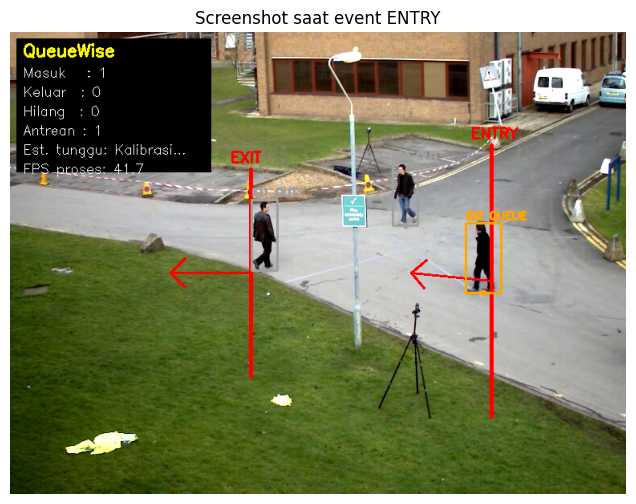

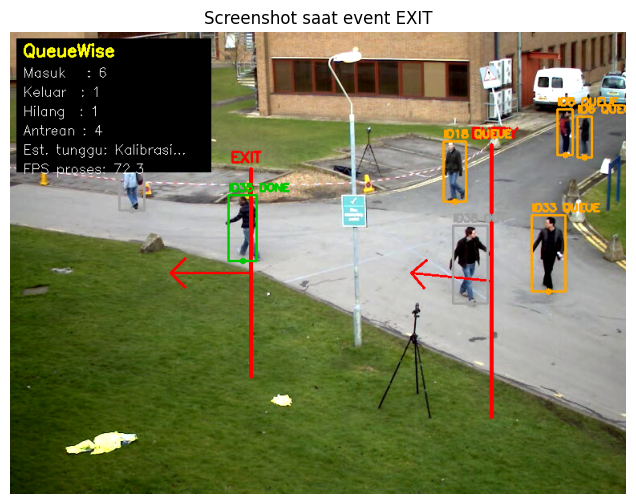

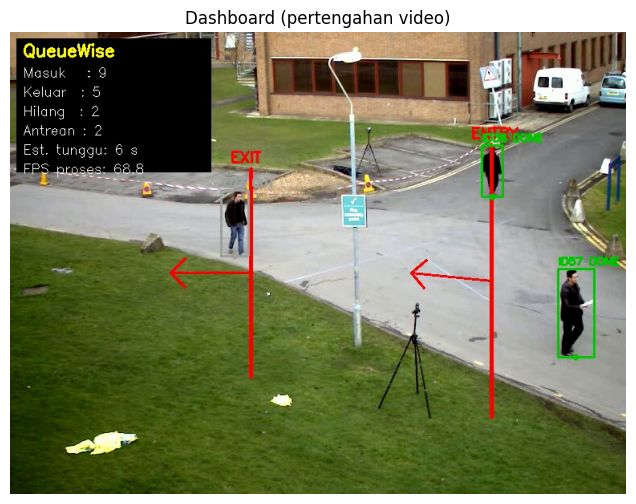

event
ENTRY                          18
EXIT                           11
EXIT_IGNORED_NOT_REGISTERED     7
LOST                            6
 frame  time_s                       event  track_id  queue  wait_s
     8     0.8                       ENTRY         2    1.0     NaN
    40     4.0                       ENTRY         5    2.0     NaN
    45     4.5                       ENTRY         6    3.0     NaN
    73     7.3 EXIT_IGNORED_NOT_REGISTERED        25    NaN     NaN
    74     7.4                       ENTRY        18    4.0     NaN
    74     7.4                        LOST         2    3.0     NaN
   133    13.3                       ENTRY        33    4.0     NaN
   152    15.2                       ENTRY        35    5.0     NaN
   171    17.1 EXIT_IGNORED_NOT_REGISTERED        43    NaN     NaN
   190    19.0                        EXIT        35    4.0     3.8
   222    22.2                       ENTRY        38    5.0     NaN
   233    23.3                        EXIT

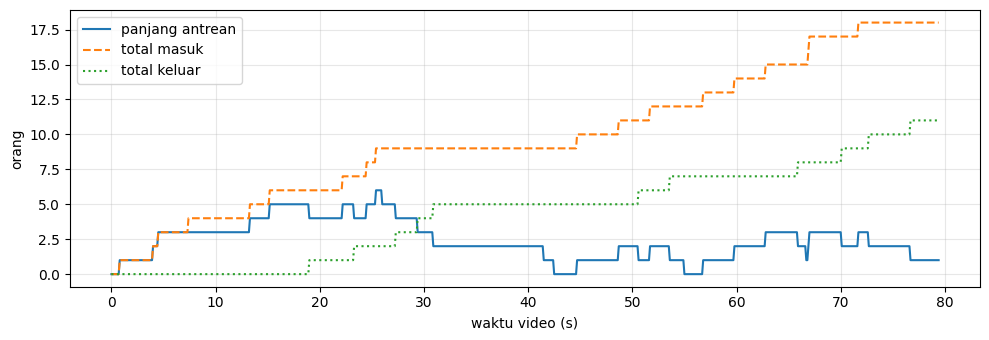

In [102]:
EVENTS = pd.DataFrame(qc.events); TIMELINE = pd.DataFrame(timeline)
EVENTS.to_csv(OUT / "event_log.csv", index=False); TIMELINE.to_csv(OUT / "timeline.csv", index=False)

for name, img in snapshots.items():
    cv2.imwrite(str(OUT / f"screenshots/03_event_{name}.jpg"), img)
    show(img, f"Screenshot saat event {name}")
# screenshot dashboard di tengah video
cap = cv2.VideoCapture(str(OUT / "queuewise_output.mp4")); cap.set(cv2.CAP_PROP_POS_FRAMES, f // 2)
ok, mid = cap.read(); cap.release()
if ok:
    cv2.imwrite(str(OUT / "screenshots/04_dashboard_tengah.jpg"), mid); show(mid, "Dashboard (pertengahan video)")

print(EVENTS.event.value_counts().to_string())
print(EVENTS.head(15).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(TIMELINE.time_s, TIMELINE.queue, label="panjang antrean")
ax.plot(TIMELINE.time_s, TIMELINE.entries, "--", label="total masuk")
ax.plot(TIMELINE.time_s, TIMELINE.exits, ":", label="total keluar")
ax.set_xlabel("waktu video (s)"); ax.set_ylabel("orang"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "screenshots/05_grafik_antrean.png"); plt.show()

## 9. Evaluasi awal
1. **Unit test sintetis** (bagian 6).
2. **Kecepatan proses** (FPS end-to-end di perangkat ini).
3. **Estimasi vs waktu tunggu aktual**: untuk tiap orang yang masuk lalu keluar, estimasi saat ia masuk dibandingkan
   dengan waktu tunggu terukur → MAE.
4. **Akurasi counting vs ground truth manual**: isi `GT_ENTRIES` dan `GT_EXITS` setelah menonton video
   (hitung orang yang melewati garis dengan arah benar). Selama masih `None`, akurasi belum bisa diklaim.

In [103]:
lat = np.array(latencies)
print(f"FPS proses rata-rata: {1 / lat.mean():.1f} | latensi median {np.median(lat) * 1000:.0f} ms | p95 {np.percentile(lat, 95) * 1000:.0f} ms")
print(f"FPS video: {FPS:.1f} -> {'real-time' if 1 / lat.mean() >= FPS else 'belum real-time'} di perangkat ini")

# 3) estimasi saat masuk vs waktu tunggu aktual
ent = EVENTS[EVENTS.event == "ENTRY"][["track_id", "frame"]].rename(columns={"frame": "f_in"})
ext = EVENTS[EVENTS.event == "EXIT"][["track_id", "wait_s"]]
cmp_ = ent.merge(ext, on="track_id")
cmp_["est_saat_masuk_s"] = [TIMELINE.est_wait_s.iloc[fi] for fi in cmp_.f_in]
cmp_ = cmp_.dropna()
if len(cmp_):
    cmp_["abs_err_s"] = (cmp_.est_saat_masuk_s - cmp_.wait_s).abs()
    print(cmp_.round(1).to_string(index=False))
    print(f"MAE estimasi waktu tunggu: {cmp_.abs_err_s.mean():.1f} s (n={len(cmp_)})")
else:
    print("Belum ada pasangan estimasi-aktual (estimasi masih Kalibrasi).")

# 4) ground truth manual
GT_ENTRIES, GT_EXITS = None, None      # isi dari hitungan manual kelompok
if GT_ENTRIES is None:
    print("Ground truth manual: BELUM DIISI -> akurasi counting belum bisa diklaim.")
else:
    for name, pred, gt in (("entries", qc.entries, GT_ENTRIES), ("exits", qc.exits, GT_EXITS)):
        print(f"{name}: prediksi {pred} vs GT {gt} | error {abs(pred - gt)} | akurasi {1 - abs(pred - gt) / gt:.1%}")

print(f"\nTrack ID unik di video: {len(qc.last_seen)} | exit tanpa registrasi: {(EVENTS.event == 'EXIT_IGNORED_NOT_REGISTERED').sum()}")

FPS proses rata-rata: 74.0 | latensi median 13 ms | p95 15 ms
FPS video: 10.0 -> real-time di perangkat ini
 track_id  f_in  wait_s  est_saat_masuk_s  abs_err_s
       55   245     4.9              21.5       16.6
       57   254     5.5              25.8       20.3
       77   447     5.9               3.0        2.9
       85   517     1.9              12.6       10.7
      100   598     6.1              11.5        5.4
       97   669     5.8              13.4        7.6
      112   670     3.1              20.1       17.0
      114   717     5.0              19.2       14.2
MAE estimasi waktu tunggu: 11.8 s (n=8)
Ground truth manual: BELUM DIISI -> akurasi counting belum bisa diklaim.

Track ID unik di video: 36 | exit tanpa registrasi: 7


## 10. Keterbatasan & rencana Week 9
- `vtest.avi` bukan antrean: "waktu tunggu" yang terukur sebenarnya waktu jalan di antara dua garis.
- ID switch dari ByteTrack bisa membuat orang yang sama keluar dengan ID baru → exit diabaikan, ID lama menjadi LOST.
- Orang yang sudah berada di antara garis saat video mulai tidak terhitung masuk.
- Estimasi waktu tunggu masih model sederhana (1 loket, FIFO, selang keluar rata-rata).

**Week 9:** rekam video antrean nyata (dengan izin), atur ulang koordinat garis, isi ground truth manual,
bandingkan ByteTrack vs BoT-SORT, dan (opsional) tampilkan dashboard dengan Streamlit.

## 11. Demo video hasil
Memutar video hasil proses (kotak per status, dua garis merah, dan dashboard) langsung di notebook.
Video `mp4v` dari OpenCV **tidak bisa diputar di browser**, jadi sel ini mengonversinya ke H.264 dengan `ffmpeg`
(sudah tersedia di Colab). Jika `ffmpeg` tidak ada, sel menampilkan cuplikan frame sebagai gantinya.

In [104]:
import base64, shutil, subprocess
from IPython.display import HTML, display

RAW  = OUT / "queuewise_output.mp4"        # keluaran pipeline (mp4v)
DEMO = OUT / "queuewise_demo_h264.mp4"     # versi yang bisa diputar di browser

def to_h264(src, dst):
    if shutil.which("ffmpeg") is None:
        return False
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(src), "-c:v", "libx264", "-crf", "26",
                    "-preset", "veryfast", "-pix_fmt", "yuv420p", "-movflags", "+faststart", str(dst)], check=False)
    return dst.exists() and dst.stat().st_size > 0

assert RAW.exists(), "Video hasil belum ada -> jalankan dulu sel pipeline utama (bagian 7)."

if to_h264(RAW, DEMO):
    b64 = base64.b64encode(DEMO.read_bytes()).decode()
    display(HTML(f"""<video width="{W}" controls autoplay loop muted playsinline
        src="data:video/mp4;base64,{b64}"></video>"""))
    print(f"Demo: {DEMO} ({DEMO.stat().st_size / 1e6:.1f} MB) | {f} frame @ {FPS:.0f} FPS | "
          f"akhir: masuk={qc.entries}, keluar={qc.exits}, hilang={qc.lost}")
else:
    # Cadangan tanpa ffmpeg: 6 frame cuplikan dari video hasil
    print("ffmpeg tidak ditemukan -> menampilkan cuplikan frame.")
    cap = cv2.VideoCapture(str(RAW)); n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, i in zip(axes.ravel(), np.linspace(0, n - 1, 6).astype(int)):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i)); ok, fr = cap.read()
        ax.imshow(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)); ax.set_title(f"t = {i / FPS:.1f} s"); ax.axis("off")
    cap.release(); plt.tight_layout(); plt.show()

Demo: outputs/queuewise_demo_h264.mp4 (3.9 MB) | 795 frame @ 10 FPS | akhir: masuk=18, keluar=11, hilang=6


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>